In [ ]:
# ----------------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# ----------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ----------------------------------------------------------------------------
# 1. Data 
# ----------------------------------------------------------------------------
X = np.load('..\Function_4_Data\Week_10_Data/F4_Week_10_inputs.npy')
y = np.load('..\Function_4_Data\Week_10_Data/F4_Week_10_outputs.npy')
n, d = X.shape
N_INITIAL = 30   # REV R3: rows 1-30 are the initial design, the rest were queried
BOUNDS = np.array([[0.0, 1.0]] * d)
best_idx = int(np.argmax(y))

2. TARGET TRANSFORMATION
y (raw):          mean=-14.602876  std=9.133496  min=-32.625660  max=0.615945
y (standardised): mean=-0.000000  std=1.000000  min=-1.973262  max=1.666265


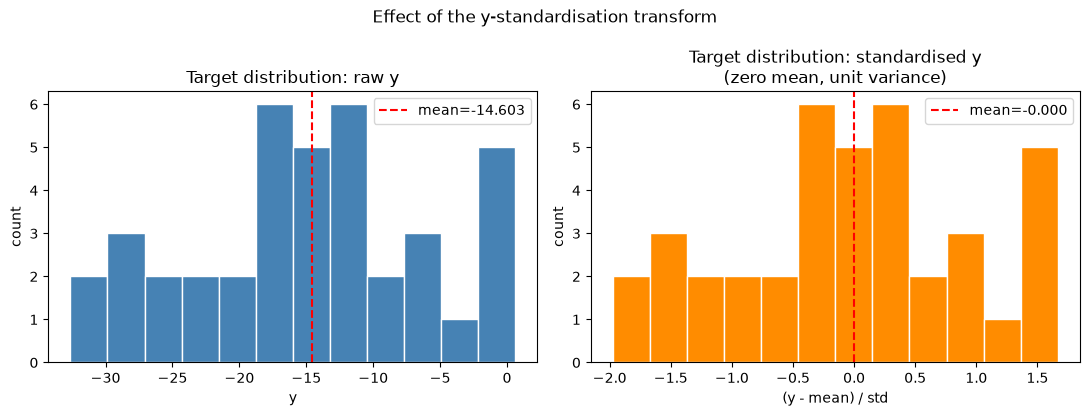

In [3]:
# ----------------------------------------------------------------------------
# 2. Data transformation + before/after plot
# ----------------------------------------------------------------------------
y_mean, y_std = y.mean(), y.std()
y_train = (y - y_mean) / y_std

def to_standard(y_raw):
    return (y_raw - y_mean) / y_std

def from_standard(y_s):
    return y_s * y_std + y_mean


print("=" * 100)
print("2. TARGET TRANSFORMATION")
print("=" * 100)
print(f"y (raw):          mean={y.mean():.6f}  std={y.std():.6f}  "
      f"min={y.min():.6f}  max={y.max():.6f}")
print(f"y (standardised): mean={y_train.mean():.6f}  std={y_train.std():.6f}  "
      f"min={y_train.min():.6f}  max={y_train.max():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="white")
axes[0].axvline(y.mean(), color="red", linestyle="--", label=f"mean={y.mean():.3f}")
axes[0].set_title("Target distribution: raw y")
axes[0].set_xlabel("y"); axes[0].set_ylabel("count"); axes[0].legend()

axes[1].hist(y_train, bins=12, color="darkorange", edgecolor="white")
axes[1].axvline(y_train.mean(), color="red", linestyle="--",
                label=f"mean={y_train.mean():.3f}")
axes[1].set_title("Target distribution: standardised y\n(zero mean, unit variance)")
axes[1].set_xlabel("(y - mean) / std"); axes[1].set_ylabel("count"); axes[1].legend()
fig.suptitle("Effect of the y-standardisation transform")
fig.tight_layout()

In [4]:
# ----------------------------------------------------------------------------
# 3. Surrogate: re-check isotropic vs ARD on all points
# ----------------------------------------------------------------------------
def loo_eval(fixed_kernel):
    mean_raw = np.zeros(n); std_raw = np.zeros(n); lpd = np.zeros(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool); mask[i] = False
        gp_loo = GaussianProcessRegressor(kernel=fixed_kernel, optimizer=None, normalize_y=False)
        gp_loo.fit(X[mask], y_train[mask])
        m, s = gp_loo.predict(X[i:i + 1], return_std=True)
        s = max(s[0], 1e-9)
        mean_raw[i] = m[0] * y_std + y_mean
        std_raw[i] = s * y_std
        lpd[i] = -0.5 * np.log(2 * np.pi * s ** 2) - 0.5 * ((y_train[i] - m[0]) ** 2) / s ** 2
    rmse = np.sqrt(np.mean((y - mean_raw) ** 2))
    return rmse, lpd.mean(), mean_raw, std_raw


iso_kernel = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e1), nu=2.5)
              + WhiteKernel(1e-4, (1e-10, 1e-1)))
ard_kernel = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=[0.3] * d, length_scale_bounds=(1e-2, 1e1), nu=2.5)
              + WhiteKernel(1e-4, (1e-10, 1e-1)))

gp_iso = GaussianProcessRegressor(kernel=iso_kernel, n_restarts_optimizer=30,
                                   normalize_y=False, random_state=SEED).fit(X, y_train)
gp_ard = GaussianProcessRegressor(kernel=ard_kernel, n_restarts_optimizer=30,
                                   normalize_y=False, random_state=SEED).fit(X, y_train)

rmse_iso, lpd_iso, loo_mean_iso, loo_std_iso = loo_eval(gp_iso.kernel_)
rmse_ard, lpd_ard, loo_mean_ard, loo_std_ard = loo_eval(gp_ard.kernel_)

print("=" * 100)
print("3. SURROGATE & ACQUISITION RE-TUNING FOR EXPLOITATION")
print("=" * 100)
print(f"Isotropic: {gp_iso.kernel_}")
print(f"  LOO-RMSE={rmse_iso:.6f}  LOO-meanLPD={lpd_iso:.6f}")
print(f"ARD:       {gp_ard.kernel_}")
print(f"  LOO-RMSE={rmse_ard:.6f}  LOO-meanLPD={lpd_ard:.6f}")
# REV R1: the model choice is computed (lower LOO-RMSE), not asserted.
use_ard = rmse_ard <= rmse_iso
model_name = "ARD" if use_ard else "Isotropic"
gp = gp_ard if use_ard else gp_iso
rmse_sel, lpd_sel = (rmse_ard, lpd_ard) if use_ard else (rmse_iso, lpd_iso)
loo_mean_raw, loo_std_raw = (loo_mean_ard, loo_std_ard) if use_ard else (loo_mean_iso, loo_std_iso)
print(f"-> {model_name} selected (lower LOO-RMSE: ARD {rmse_ard:.6f} vs isotropic {rmse_iso:.6f}; "
      f"LOO-RMSE / std(y) = {rmse_sel / y_std:.6f}).")

ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
noise_var = gp.kernel_.k2.noise_level            # standardised units
print(f"\nLearned {model_name} length-scales: {np.round(ls, 6).tolist()}")
print(f"Fitted noise std (raw y units): {np.sqrt(noise_var) * y_std:.6f}")
if np.all(ls > 1.0):
    print("All length-scales exceed the domain width (1.0): the kernel is smooth/global.")
else:
    print(f"Length-scales below the domain width (1.0): dims {(np.where(ls <= 1.0)[0] + 1).tolist()}.")
for v, tag in zip(ls, [f"x{j+1}" for j in range(len(ls))]):
    if np.isclose(v, 1e-2, rtol=1e-3) or np.isclose(v, 1e1, rtol=1e-3):
        print(f"  WARNING: {tag} length-scale ({v:.6f}) is on an optimisation bound.")



3. SURROGATE & ACQUISITION RE-TUNING FOR EXPLOITATION
Isotropic: 2.41**2 * Matern(length_scale=1.35, nu=2.5) + WhiteKernel(noise_level=0.000243)
  LOO-RMSE=1.617246  LOO-meanLPD=0.666690
ARD:       2.54**2 * Matern(length_scale=[1.37, 1.5, 1.35, 1.37], nu=2.5) + WhiteKernel(noise_level=0.000253)
  LOO-RMSE=1.558540  LOO-meanLPD=0.690118
-> ARD selected (lower LOO-RMSE: ARD 1.558540 vs isotropic 1.617246; LOO-RMSE / std(y) = 0.170640).

Learned ARD length-scales: [1.365383, 1.502409, 1.347673, 1.374216]
Fitted noise std (raw y units): 0.145224
All length-scales exceed the domain width (1.0): the kernel is smooth/global.


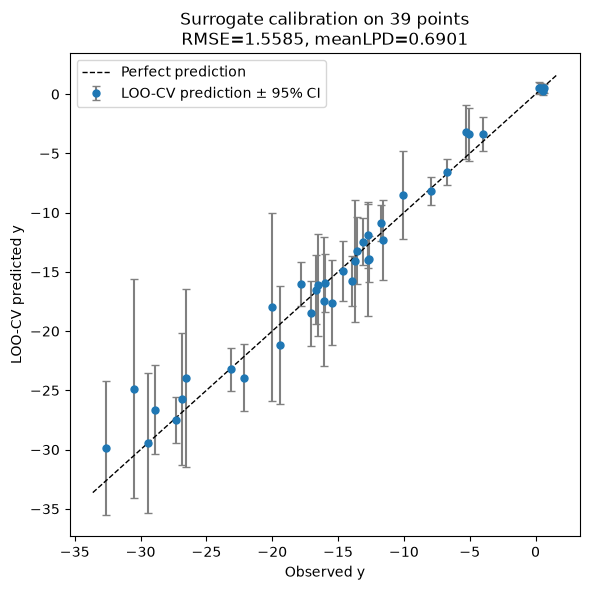

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
order = np.argsort(y)
ax.errorbar(y[order], loo_mean_raw[order], yerr=1.96 * loo_std_raw[order],
            fmt="o", ecolor="gray", capsize=3, markersize=5,
            label="LOO-CV prediction ± 95% CI")
lims = [min(y.min(), loo_mean_raw.min()) - 1, max(y.max(), loo_mean_raw.max()) + 1]
ax.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
ax.set_xlabel("Observed y"); ax.set_ylabel("LOO-CV predicted y")
ax.set_title(f"Surrogate calibration on {n} points\nRMSE={rmse_sel:.4f}, meanLPD={lpd_sel:.4f}")
ax.legend()
fig.tight_layout()

In [ ]:
# Exploitation-oriented acquisition settings 
# Changes relative to the previous configuration, and why:
#
#  1. xi: Lowered from 0.01 -> 0.005 (half the previous value) rather than exactly 0.
#  2. Trust region:  Instead of letting the acquisition optimiser roam the full unit 
#     cube, we restrict it to a box of half-width r=0.12 around the current best point 
#     (clipped to stay inside [0,1]^4). This concentrates the next query near the 
#     known-good region by construction, regardless of what the (possibly overconfident)
#     global surrogate says elsewhere.
#  3. Acquisition function: keep log(EI) (not raw EI) for numerical stability, for the
#     same reason as before -- raw EI still underflows once the incumbent is this good.

xi = 0.005
trust_radius = 0.12
lower = np.clip(X[best_idx] - trust_radius, 0.0, 1.0)
upper = np.clip(X[best_idx] + trust_radius, 0.0, 1.0)
TRUST_BOUNDS = np.stack([lower, upper], axis=1)

print(f"\nExploitation settings: xi={xi:.6f}, trust-region radius={trust_radius:.6f}")
print(f"Trust region (per dimension): {np.round(TRUST_BOUNDS, 6).tolist()}")

mu_train = gp.predict(X)
inc_idx = int(np.argmax(mu_train))
f_best = mu_train[inc_idx]
print(f"\nEI baseline: best posterior mean at an observed point = {from_standard(f_best):.6f} "
      f"(row {inc_idx+1}); noisy best observation = {y[best_idx]:.6f} (row {best_idx+1})")


def latent_posterior(x, gp_model):
    mu, sigma = gp_model.predict(np.atleast_2d(x), return_std=True)
    return mu, np.sqrt(np.maximum(sigma ** 2 - gp_model.kernel_.k2.noise_level, 1e-24))


def expected_improvement(x, gp_model, f_best, xi):
    mu, sigma = latent_posterior(x, gp_model)
    imp = mu - f_best - xi
    z_ = imp / sigma
    ei = imp * norm.cdf(z_) + sigma * norm.pdf(z_)
    return np.maximum(ei, 0.0)


def neg_log_ei(x, gp_model, f_best, xi):
    mu, sigma = latent_posterior(x, gp_model)
    sigma = sigma[0]
    z_ = (mu[0] - f_best - xi) / sigma
    if z_ > -6:
        h = z_ * norm.cdf(z_) + norm.pdf(z_)
        log_h = np.log(max(h, 1e-300))
    else:
        log_h = -0.5 * z_ ** 2 - np.log(np.sqrt(2 * np.pi)) - np.log(z_ ** 2 + 1e-12)
    return -(log_h + np.log(sigma))


N_RESTARTS = 150


def optimise_log_ei(search_bounds, seed=SEED):
    """Multi-start L-BFGS-B on -log(EI); starts are uniform in search_bounds
    plus the observed points that lie inside it. Own RNG per call."""
    rng_local = np.random.default_rng(seed)
    x0s = rng_local.uniform(search_bounds[:, 0], search_bounds[:, 1], size=(N_RESTARTS, d))
    inside = np.all((X >= search_bounds[:, 0]) & (X <= search_bounds[:, 1]), axis=1)
    x0s = np.vstack([x0s, X[inside]])
    bx, bv = None, np.inf
    for x0 in x0s:
        res = minimize(neg_log_ei, x0, args=(gp, f_best, xi), bounds=search_bounds, method="L-BFGS-B")
        if res.fun < bv:
            bv, bx = res.fun, res.x
    return bx, bv


best_x, best_val = optimise_log_ei(TRUST_BOUNDS)

# Same search without the trust region, to see whether it binds.
global_x, global_val = optimise_log_ei(BOUNDS)
tr_binds = np.linalg.norm(global_x - best_x) > 1e-3
print(f"\nFull-domain log-EI optimum: {np.round(global_x, 6).tolist()}  log EI = {-global_val:.6f}")
print("-> the trust region CHANGES the proposal (the unconstrained optimum lies elsewhere)."
      if tr_binds else
      "-> same point as the trust-region search: the trust region is not constraining the result.")

next_x = best_x
next_ei = np.exp(-best_val)
mu_n, sig_n = latent_posterior(next_x, gp)
next_mu = from_standard(mu_n)[0]
next_sigma = sig_n[0] * y_std

print("\n" + "=" * 78)
print("4. RESULT (exploitation-biased next query, 6 decimal places)")
print("=" * 78)
print(f"x*          = {np.round(next_x, 6).tolist()}")
print(f"EI(x*)      = {next_ei:.6f}")
print(f"log EI(x*)  = {-best_val:.6f}")
print(f"predicted y = {next_mu:.6f}")
print(f"predicted s = {next_sigma:.6f}")
print(f"distance to current incumbent = {np.linalg.norm(next_x - X[best_idx]):.6f}")

print(f"\nFor reference -- current best observed point:")
print(f"x_best = {np.round(X[best_idx], 6).tolist()}")
print(f"y_best = {y[best_idx]:.6f}")

print(f"\n{model_name} length-scales (6dp): {np.round(ls, 6).tolist()}")
print(f"LOO-CV RMSE ({model_name}, 6dp): {rmse_sel:.6f}   mean log predictive density: {lpd_sel:.6f}")


Exploitation settings: xi=0.005000, trust-region radius=0.120000
Trust region (per dimension): [[0.302604, 0.542604], [0.252638, 0.492638], [0.286408, 0.526408], [0.306606, 0.546606]]

EI baseline: best posterior mean at an observed point = 0.552985 (row 38); noisy best observation = 0.615945 (row 38)

Full-domain log-EI optimum: [0.44078, 0.366185, 0.403976, 0.444118]  log EI = -5.665500
-> same point as the trust-region search: the trust region is not constraining the result.

4. RESULT (exploitation-biased next query, 6 decimal places)
x*          = [0.440781, 0.366185, 0.403976, 0.444117]
EI(x*)      = 0.003463
log EI(x*)  = -5.665500
predicted y = 0.510644
predicted s = 0.166915
distance to current incumbent = 0.026165

For reference -- current best observed point:
x_best = [0.422604, 0.372638, 0.406408, 0.426606]
y_best = 0.615945

ARD length-scales (6dp): [1.365383, 1.502409, 1.347673, 1.374216]
LOO-CV RMSE (ARD, 6dp): 1.558540   mean log predictive density: 0.690118


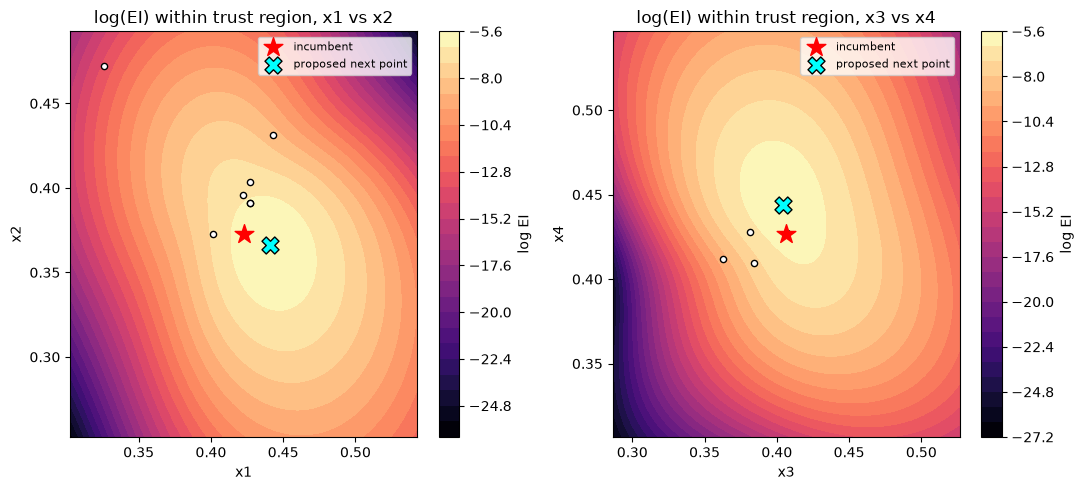

In [7]:
# local 2D slices of log-EI within the trust region, through the incumbent
grid_n = 80
pairs = [(0, 1), (2, 3)]
fixed_point = X[best_idx]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for k, (i, j) in enumerate(pairs):
    li = np.linspace(TRUST_BOUNDS[i, 0], TRUST_BOUNDS[i, 1], grid_n)
    lj = np.linspace(TRUST_BOUNDS[j, 0], TRUST_BOUNDS[j, 1], grid_n)
    Gi, Gj = np.meshgrid(li, lj)
    grid = np.tile(fixed_point, (grid_n * grid_n, 1))
    grid[:, i] = Gi.ravel(); grid[:, j] = Gj.ravel()
    ei_grid = expected_improvement(grid, gp, f_best, xi).reshape(grid_n, grid_n)
    ax = axes[k]
    cf = ax.contourf(Gi, Gj, np.log(ei_grid + 1e-15), levels=25, cmap="magma")
    ax.scatter(X[:, i], X[:, j], c="white", edgecolor="black", s=20)
    ax.scatter(fixed_point[i], fixed_point[j], marker="*", c="red", s=200, label="incumbent")
    if abs(next_x[i] - fixed_point[i]) > 1e-9 or abs(next_x[j] - fixed_point[j]) > 1e-9:
        ax.scatter(next_x[i], next_x[j], marker="X", c="cyan", s=150, edgecolor="black",
                   label="proposed next point")
    ax.set_xlim(TRUST_BOUNDS[i]); ax.set_ylim(TRUST_BOUNDS[j])
    ax.set_xlabel(f"x{i+1}"); ax.set_ylabel(f"x{j+1}")
    ax.set_title(f"log(EI) within trust region, x{i+1} vs x{j+1}")
    fig.colorbar(cf, ax=ax, label="log EI")
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()

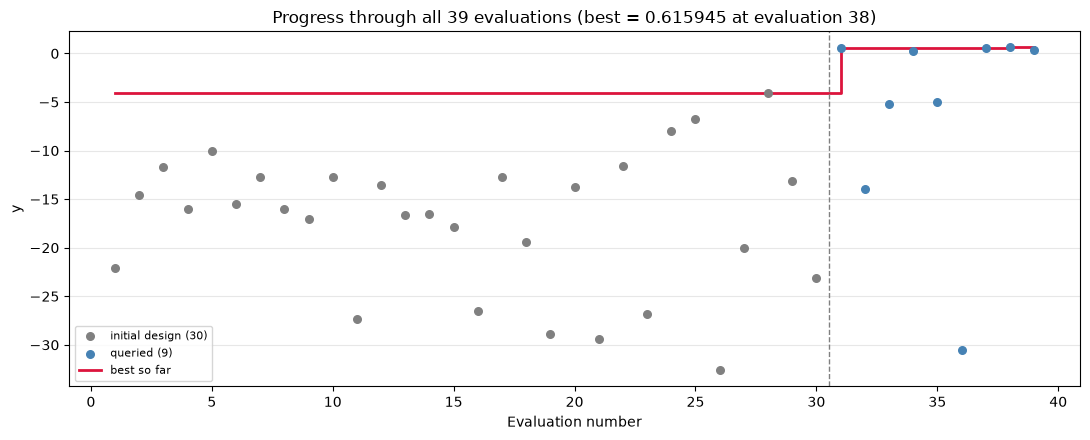

In [8]:
# Progress so far
fig, ax = plt.subplots(figsize=(11, 4.5))
evals = np.arange(1, n + 1)
running_best = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
ax.scatter(evals[:N_INITIAL], y[:N_INITIAL], c="gray", s=30, zorder=3, label=f"initial design ({N_INITIAL})")
ax.scatter(evals[N_INITIAL:], y[N_INITIAL:], c="steelblue", s=30, zorder=3, label=f"queried ({n - N_INITIAL})")
ax.step(evals, running_best, where="post", lw=2, color="crimson", zorder=2, label="best so far")
ax.axvline(N_INITIAL + 0.5, color="gray", ls="--", lw=1)
ax.set_xlabel("Evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Progress through all {n} evaluations (best = {y[best_idx]:.6f} at evaluation {best_idx+1})")
ax.legend(fontsize=8, loc="lower left"); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()